In [1]:
import pandas as pd
from rendimiento_bachoco.config import * #import DGSIAP_START_YEAR, DGSIAP_END_YEAR
import seaborn as sns
import matplotlib.pyplot as plt

2026-10-27 17:41:37.129 | INFO     | rendimiento_bachoco.config:<module>:15 - La ruta de PROJ_ROOT es: /Users/marcoramonet/Documents/MCD/IC/Rendimiento_Bursatil_Sector_Agropecuario


In [2]:
dgsiap_df = pd.DataFrame()
for year in range(DGSIAP_START_YEAR, DGSIAP_END_YEAR):
    df = pd.read_csv(INTERIM_DATA_DIR / 'DGSIAP'/ f'{year}.csv')
    dgsiap_df = pd.concat([dgsiap_df, df])


In [3]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

In [4]:
dgsiap_df.columns

Index(['Unnamed: 0', 'Anio', 'Idestado', 'Nomestado', 'Idddr', 'Nomddr',
       'Idcader', 'Nomcader', 'Idmunicipio', 'Nommunicipio', 'Idciclo',
       'Nomcicloproductivo', 'Idmodalidad', 'Nommodalidad', 'Idunidadmedida',
       'Nomunidad', 'Idcultivo', 'Nomcultivo', 'Sembrada', 'Cosechada',
       'Siniestrada', 'Volumenproduccion', 'Rendimiento', 'Precio',
       'Valorproduccion', 'Nomcultivo Sin Um', 'Preciomediorural'],
      dtype='str')

In [5]:
dgsiap_df['Nomcultivo'].value_counts()

Nomcultivo
Maíz grano                    27619
Avena forrajera en verde       9150
Maíz forrajero en verde        4421
Trigo grano                    4006
Avena grano                     687
Arroz palay                     571
Trigo forrajero verde           200
Semilla de avena grano           68
Avena forrajera achicalada       10
Avena forrajera seca              1
Name: count, dtype: int64

In [6]:
maiz = dgsiap_df.loc[(dgsiap_df['Nomcultivo'] == 'Maíz grano') | (dgsiap_df['Nomcultivo Sin Um'] == 'Maíz grano')]

In [7]:
maiz.columns

Index(['Unnamed: 0', 'Anio', 'Idestado', 'Nomestado', 'Idddr', 'Nomddr',
       'Idcader', 'Nomcader', 'Idmunicipio', 'Nommunicipio', 'Idciclo',
       'Nomcicloproductivo', 'Idmodalidad', 'Nommodalidad', 'Idunidadmedida',
       'Nomunidad', 'Idcultivo', 'Nomcultivo', 'Sembrada', 'Cosechada',
       'Siniestrada', 'Volumenproduccion', 'Rendimiento', 'Precio',
       'Valorproduccion', 'Nomcultivo Sin Um', 'Preciomediorural'],
      dtype='str')

In [8]:
maiz.dtypes

Unnamed: 0              int64
Anio                    int64
Idestado                int64
Nomestado                 str
Idddr                   int64
Nomddr                    str
Idcader                 int64
Nomcader                  str
Idmunicipio             int64
Nommunicipio              str
Idciclo                 int64
Nomcicloproductivo        str
Idmodalidad             int64
Nommodalidad              str
Idunidadmedida          int64
Nomunidad                 str
Idcultivo               int64
Nomcultivo                str
Sembrada              float64
Cosechada             float64
Siniestrada           float64
Volumenproduccion     float64
Rendimiento           float64
Precio                float64
Valorproduccion       float64
Nomcultivo Sin Um         str
Preciomediorural      float64
dtype: object

In [9]:
maiz.loc[maiz['Anio'] == 2015].head(5)['Nomcultivo Sin Um'].isna()


3     False
6     False
10    False
13    False
16    False
Name: Nomcultivo Sin Um, dtype: bool

In [10]:
maiz.loc[maiz['Anio'] == 2015].head(5)['Nomcultivo'].isna()

3     True
6     True
10    True
13    True
16    True
Name: Nomcultivo, dtype: bool

In [11]:
maiz_vol_est = maiz.groupby(['Nomestado', 'Anio'])['Volumenproduccion'].agg('mean').reset_index()
maiz_vol_nac = maiz_vol_est.groupby(['Anio'])['Volumenproduccion'].sum()
maiz_vol_nac

Anio
2013    204390.574638
2014    214779.852946
2015    210548.577667
2016    242375.774051
2017    241289.592566
2018    238206.804660
2019    240090.630547
2020    230979.241091
2021    246793.159959
2022    231966.501678
2023    236390.380498
2024    215860.400102
Name: Volumenproduccion, dtype: float64

<Axes: xlabel='Anio', ylabel='Volumenproduccion'>

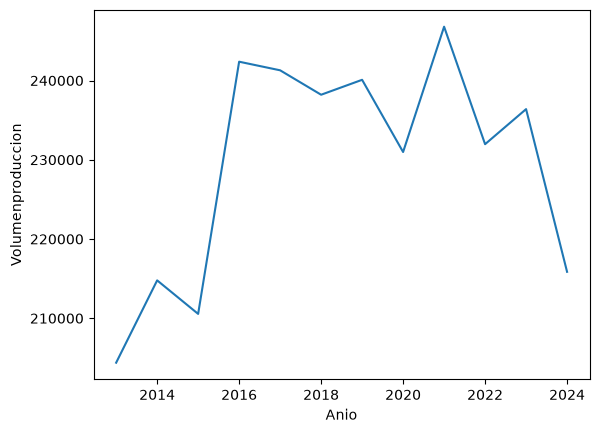

In [12]:
sns.lineplot(data=maiz_vol_nac)   

In [13]:
maiz['Precio'] = maiz['Precio'].fillna(maiz['Preciomediorural'])
maiz['Precio'].isna().sum()


np.int64(19)

In [14]:
maiz_precio_est = maiz.groupby(['Nomestado', 'Anio'])['Precio'].mean().reset_index()
maiz_precio_nac = maiz_precio_est.groupby('Anio')['Precio'].mean()
maiz_precio_nac

Anio
2013    3675.088675
2014    3319.982891
2015    3520.104177
2016    3611.532085
2017    3711.861815
2018    3892.043517
2019    4029.334369
2020    4259.213099
2021    4923.513339
2022    5910.432593
2023    6014.975461
2024    5521.533125
Name: Precio, dtype: float64

<Axes: xlabel='Anio', ylabel='Precio'>

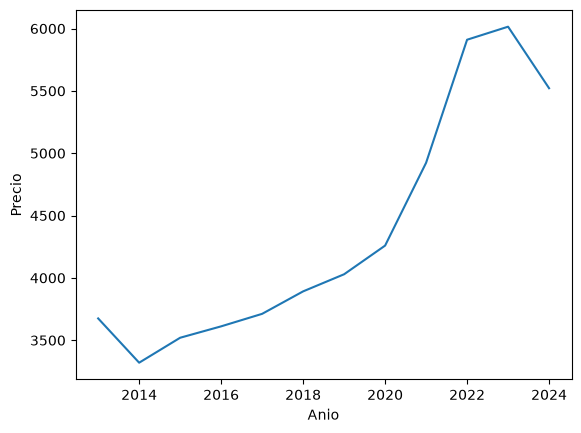

In [15]:
sns.lineplot(data=maiz_precio_nac) 

Text(0.5, 1.0, 'Maíz grano: volumen vs precio')

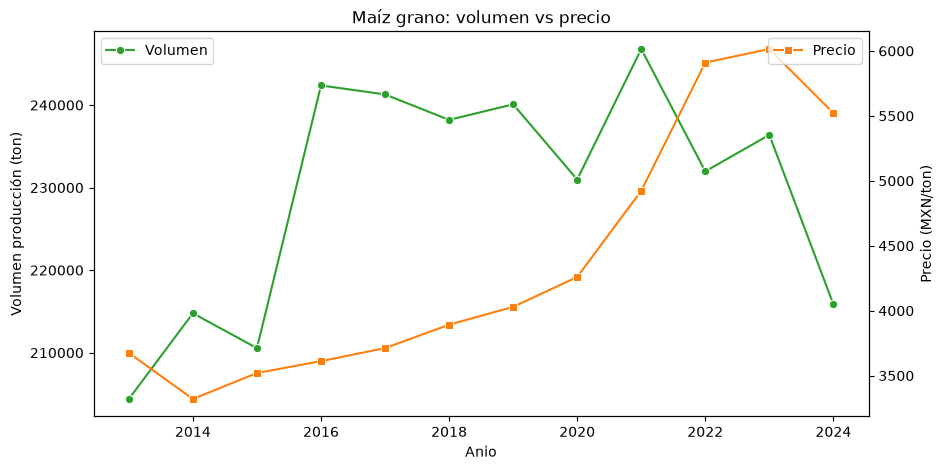

In [16]:
fig, ax1 = plt.subplots(figsize=(10, 5))
sns.lineplot(data=maiz_vol_nac, ax=ax1, color='tab:green', marker='o', label='Volumen')
ax1.set_ylabel('Volumen producción (ton)')

ax2 = ax1.twinx()
sns.lineplot(data=maiz_precio_nac, ax=ax2, color='tab:orange', marker='s', label='Precio')
ax2.set_ylabel('Precio (MXN/ton)')

ax1.legend(loc='upper left'); ax2.legend(loc='upper right')
plt.title('Maíz grano: volumen vs precio')

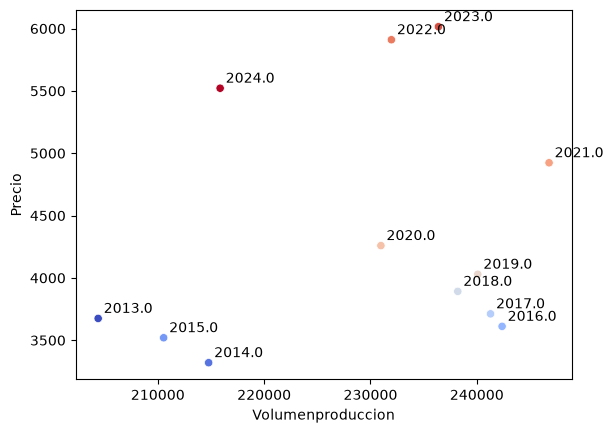

In [ ]:
nac = pd.concat([maiz_vol_nac, maiz_precio_nac], axis=1)   # aligns on Anio
nac = nac.reset_index()
nac['color_val'] = range(len(nac))
sns.scatterplot(data=nac, x='Volumenproduccion', y='Precio', hue='color_val', palette='coolwarm', legend=False)
for _, row in nac.iterrows():
    plt.annotate(row['Anio'], (row['Volumenproduccion'], row['Preco']), textcoords='offset points', xytext=(4, 4))